# Laboratorio: Modelos Generativos — Task 1 (VAE) y Task 2 (proceso forward de difusión)

**Curso:** CC3092 Deep Learning — Universidad del Valle de Guatemala

Este notebook contiene la entrega parcial (Task 1 y Task 2). Las Tasks 3 y 4 (U-Net condicional,
muestreo ancestral, guía sin clasificador y comparación de familias) van en un notebook aparte.

**Restricciones respetadas:** todo está escrito con tensores de PyTorch; solo se usan `nn.Linear`,
funciones de activación, `torch.optim.Adam` y `loss.backward()`. No se usa `diffusers`,
`torch.distributions` ni calendarios/muestreadores prefabricados: la reparametrización, la KL,
la pérdida del VAE, el calendario de ruido y el proceso forward están escritos a mano.

In [1]:
import os, math, json, time, random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd
from torchvision import datasets

# ---------------- Semilla aleatoria (se reporta en el documento) ----------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)   # reproducibilidad (avisa si alguna op no es determinista)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, os.cpu_count() or 1))
print("Dispositivo:", device, "| PyTorch", torch.__version__, "| SEED =", SEED)

os.makedirs("figs", exist_ok=True)
os.makedirs("models", exist_ok=True)
RESULTS = {"seed": SEED}          # aquí se guardan todos los números que van al documento

# Paleta: 3 colores para las tres β (orden fijo) y 10 colores + 10 marcadores para las clases
BETA_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4",
                "#008300", "#6250d6", "#e34948", "#7f7f7f", "#8c564b"]
CLASS_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">"]
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10})

def savefig(name):
    plt.savefig(f"figs/{name}.png", bbox_inches="tight")
    plt.show()

def tile(imgs, nrow, ncol, pad=1, value=1.0):
    """Arma una cuadrícula (nrow x ncol) de imágenes 28x28 en un solo arreglo para graficar."""
    imgs = imgs.reshape(-1, 28, 28).detach().cpu().numpy()
    H = nrow * 28 + (nrow + 1) * pad; W = ncol * 28 + (ncol + 1) * pad
    canvas = np.full((H, W), value, dtype=np.float32)
    for k in range(min(len(imgs), nrow * ncol)):
        r, c = divmod(k, ncol)
        y = pad + r * (28 + pad); x = pad + c * (28 + pad)
        canvas[y:y + 28, x:x + 28] = imgs[k]
    return canvas

Dispositivo: cpu | PyTorch 2.13.0+cpu | SEED = 42


## Task 1.1 — Datos
Fashion-MNIST: 60 000 imágenes de entrenamiento y 10 000 de prueba, 28×28 en escala de grises.
Se escalan los píxeles a [0, 1] y los últimos 5 000 ejemplos de entrenamiento se separan como validación.

In [2]:
train_ds = datasets.FashionMNIST("data", train=True, download=True)
test_ds = datasets.FashionMNIST("data", train=False, download=True)
print("Entrenamiento:", len(train_ds), "| Prueba:", len(test_ds))

X_all = train_ds.data.float().div(255.0).view(-1, 784)   # escala [0, 1], vector de 784 píxeles
Y_all = train_ds.targets.clone()
X_train01, Y_train = X_all[:-5000], Y_all[:-5000]       # primeros 55 000
X_val01, Y_val = X_all[-5000:], Y_all[-5000:]           # últimos 5 000 = validación
print("train:", tuple(X_train01.shape), "val:", tuple(X_val01.shape),
      "rango:", X_train01.min().item(), X_train01.max().item())

# Configuración pedida en el enunciado
batch_size = 128
latent_dim = 2
epochs = 20
lr = 1e-3
beta_values = [0.1, 1.0, 10.0]

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.91MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 246kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.56MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


Entrenamiento: 60000 | Prueba: 10000
train: (55000, 784) val: (5000, 784) rango: 0.0 1.0


## Task 1.2 — Autoencoder variacional
Encoder y decoder completamente conectados (misma arquitectura para las tres β):

* Encoder: 784 → 512 → 256 → (μ ∈ ℝ², log σ² ∈ ℝ²)  — es $q_\phi(z\mid x)=\mathcal N(\mu_\phi(x),\operatorname{diag}\sigma^2_\phi(x))$ de la diapositiva *Espacio latente y VAEs*.
* Decoder: 2 → 256 → 512 → 784 con sigmoide (salida en [0,1]) — es la media de $p_\theta(x\mid z)$.

Fórmulas escritas a mano:
* (a) reparametrización $z=\mu+\sigma\odot\epsilon,\ \epsilon\sim\mathcal N(0,I)$, con $\sigma=\exp(\tfrac12\log\sigma^2)$;
* (b) KL cerrada $D_{KL}(\mathcal N(\mu,\operatorname{diag}\sigma^2)\,\|\,\mathcal N(0,I))=\tfrac12\sum_j(\mu_j^2+\sigma_j^2-\log\sigma_j^2-1)$;
* (c) pérdida por imagen $\mathcal L_\beta=\|x-\hat x\|^2+\beta\,D_{KL}$ (error cuadrático sumado sobre los 784 píxeles).

In [3]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        # Encoder q_phi(z|x): produce dos vectores de dimensión latent_dim (μ y log σ²)
        self.enc = nn.Sequential(nn.Linear(784, 512), nn.ReLU(),
                                 nn.Linear(512, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        # Decoder p_theta(x|z): devuelve la media x̂ de la distribución de x dado z
        self.dec = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(),
                                 nn.Linear(256, 512), nn.ReLU(),
                                 nn.Linear(512, 784), nn.Sigmoid())

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparametrize(mu, logvar)
        return self.decode(z), mu, logvar


def reparametrize(mu, logvar):
    """(a) Truco de reparametrización: z = μ + σ ⊙ ε, ε ~ N(0, I).
    El azar queda en ε (sin parámetros), así el gradiente fluye por μ y σ."""
    sigma = torch.exp(0.5 * logvar)          # σ = exp(½ log σ²)
    eps = torch.randn_like(sigma)            # ε ~ N(0, I)
    return mu + sigma * eps


def kl_closed_form(mu, logvar):
    """(b) KL en forma cerrada entre q(z|x)=N(μ, diag σ²) y p(z)=N(0, I), sumada sobre dimensiones latentes:
    D_KL = ½ Σ_j ( μ_j² + σ_j² − log σ_j² − 1 ).  Devuelve un valor por imagen (en nats)."""
    return 0.5 * (mu.pow(2) + logvar.exp() - logvar - 1.0).sum(dim=1)


def vae_loss_terms(x, x_hat, mu, logvar):
    """(c) Términos de L_β por imagen: ||x − x̂||² (sumado sobre los 784 píxeles) y D_KL."""
    rec = (x - x_hat).pow(2).sum(dim=1)
    kl = kl_closed_form(mu, logvar)
    return rec, kl


@torch.no_grad()
def evaluate_vae(model, X, bs=1000):
    model.eval(); rec_sum = kl_sum = 0.0
    for i in range(0, len(X), bs):
        xb = X[i:i + bs].to(device)
        x_hat, mu, logvar = model(xb)
        rec, kl = vae_loss_terms(xb, x_hat, mu, logvar)
        rec_sum += rec.sum().item(); kl_sum += kl.sum().item()
    return rec_sum / len(X), kl_sum / len(X)


def train_vae(beta):
    # Misma semilla para cada β: la inicialización y el orden de los lotes son idénticos,
    # así la única diferencia entre los tres modelos es el valor de β.
    torch.manual_seed(SEED)
    model = VAE(latent_dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_rec": [], "val_kl": [], "val_loss": []}
    N = len(X_train01)
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(N); tot = 0.0
        for i in range(0, N, batch_size):
            xb = X_train01[perm[i:i + batch_size]].to(device)
            x_hat, mu, logvar = model(xb)
            rec, kl = vae_loss_terms(xb, x_hat, mu, logvar)
            loss = (rec + beta * kl).mean()   # L_β promediada sobre el lote
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        vrec, vkl = evaluate_vae(model, X_val01)
        hist["train_loss"].append(tot / N); hist["val_rec"].append(vrec)
        hist["val_kl"].append(vkl); hist["val_loss"].append(vrec + beta * vkl)
        if ep in (1, 5, 10, 15, 20):
            print(f"β={beta:>4} | época {ep:2d} | train L_β={tot / N:7.2f} | "
                  f"val rec={vrec:6.2f} | val KL={vkl:5.3f} nats")
    return model, hist


models, histories = {}, {}
t0 = time.time()
for beta in beta_values:
    models[beta], histories[beta] = train_vae(beta)
    torch.save(models[beta].state_dict(), f"models/vae_beta{beta}.pt")   # el β=1 se reutiliza en la Task 4.1
print(f"Tiempo total de entrenamiento: {time.time() - t0:.1f} s")
RESULTS["vae_histories"] = {str(b): h for b, h in histories.items()}

β= 0.1 | época  1 | train L_β=  32.32 | val rec= 25.96 | val KL=9.173 nats
β= 0.1 | época  5 | train L_β=  22.83 | val rec= 22.34 | val KL=8.266 nats
β= 0.1 | época 10 | train L_β=  21.58 | val rec= 21.04 | val KL=8.456 nats
β= 0.1 | época 15 | train L_β=  20.85 | val rec= 20.39 | val KL=8.017 nats
β= 0.1 | época 20 | train L_β=  20.34 | val rec= 20.13 | val KL=8.535 nats
β= 1.0 | época  1 | train L_β=  38.34 | val rec= 27.62 | val KL=4.367 nats
β= 1.0 | época  5 | train L_β=  28.33 | val rec= 24.12 | val KL=4.900 nats
β= 1.0 | época 10 | train L_β=  27.34 | val rec= 22.63 | val KL=4.870 nats
β= 1.0 | época 15 | train L_β=  26.80 | val rec= 21.67 | val KL=5.282 nats
β= 1.0 | época 20 | train L_β=  26.34 | val rec= 21.29 | val KL=5.149 nats
β=10.0 | época  1 | train L_β=  60.48 | val rec= 41.34 | val KL=1.388 nats
β=10.0 | época  5 | train L_β=  53.95 | val rec= 37.96 | val KL=1.648 nats
β=10.0 | época 10 | train L_β=  53.70 | val rec= 38.44 | val KL=1.578 nats
β=10.0 | época 15 | train

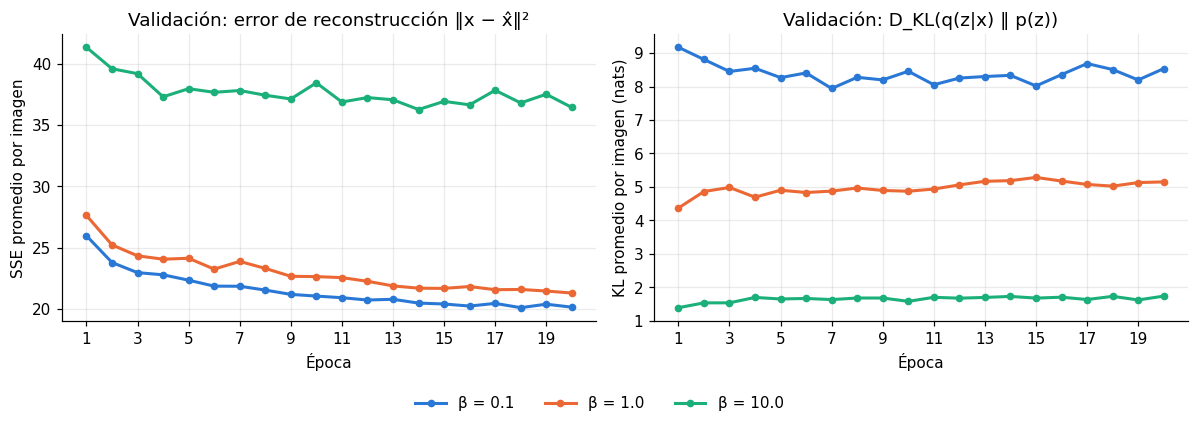

In [4]:
# Curvas de validación por época: error de reconstrucción y KL, para cada β
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ep_axis = np.arange(1, epochs + 1)
for c, beta in zip(BETA_COLORS, beta_values):
    axes[0].plot(ep_axis, histories[beta]["val_rec"], color=c, lw=2, marker="o", ms=4, label=f"β = {beta}")
    axes[1].plot(ep_axis, histories[beta]["val_kl"], color=c, lw=2, marker="o", ms=4, label=f"β = {beta}")
axes[0].set_title("Validación: error de reconstrucción ‖x − x̂‖²")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("SSE promedio por imagen")
axes[1].set_title("Validación: D_KL(q(z|x) ‖ p(z))")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("KL promedio por imagen (nats)")
for ax in axes: ax.set_xticks(ep_axis[::2] + 0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.03))
plt.tight_layout(rect=(0, 0.06, 1, 1)); savefig("t1_2_curvas_validacion")

## Task 1.3 — Figuras con los tres modelos

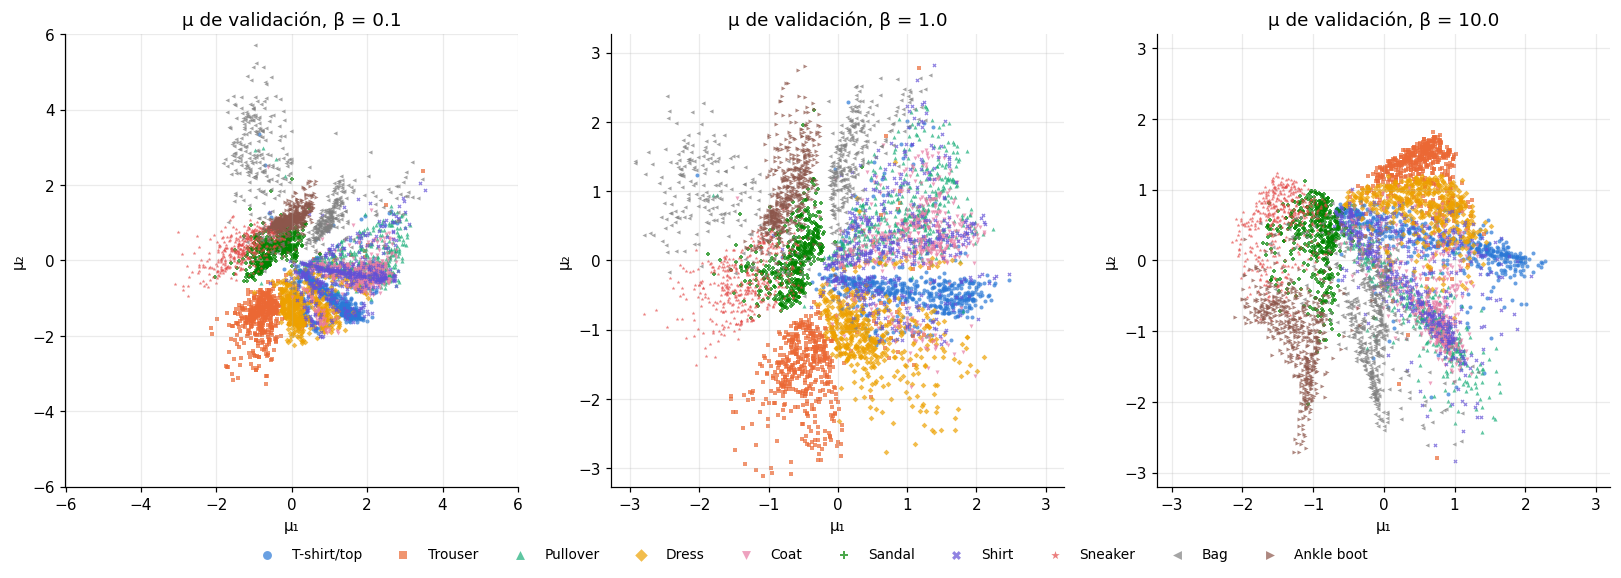

In [5]:
@torch.no_grad()
def encode_mu_logvar(model, X, bs=2500):
    model.eval(); mus, lvs = [], []
    for i in range(0, len(X), bs):
        mu, lv = model.encode(X[i:i + bs].to(device)); mus.append(mu.cpu()); lvs.append(lv.cpu())
    return torch.cat(mus), torch.cat(lvs)

val_mu = {b: encode_mu_logvar(models[b], X_val01)[0] for b in beta_values}

# (a) Dispersión de μ para las 5 000 imágenes de validación, coloreado por clase (tres paneles)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.9))
for ax, beta in zip(axes, beta_values):
    m = val_mu[beta].numpy()
    for k in range(10):
        sel = (Y_val == k).numpy()
        ax.scatter(m[sel, 0], m[sel, 1], s=7, c=CLASS_COLORS[k], marker=CLASS_MARKERS[k],
                   alpha=0.7, linewidths=0, label=CLASSES[k])
    ax.set_title(f"μ de validación, β = {beta}")
    ax.set_xlabel("μ₁"); ax.set_ylabel("μ₂")
    lim = max(3.2, np.abs(m).max() * 1.05)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=10, frameon=False, markerscale=2.2,
           bbox_to_anchor=(0.5, -0.04), fontsize=9)
plt.tight_layout(rect=(0, 0.04, 1, 1)); savefig("t1_3a_dispersion_mu")

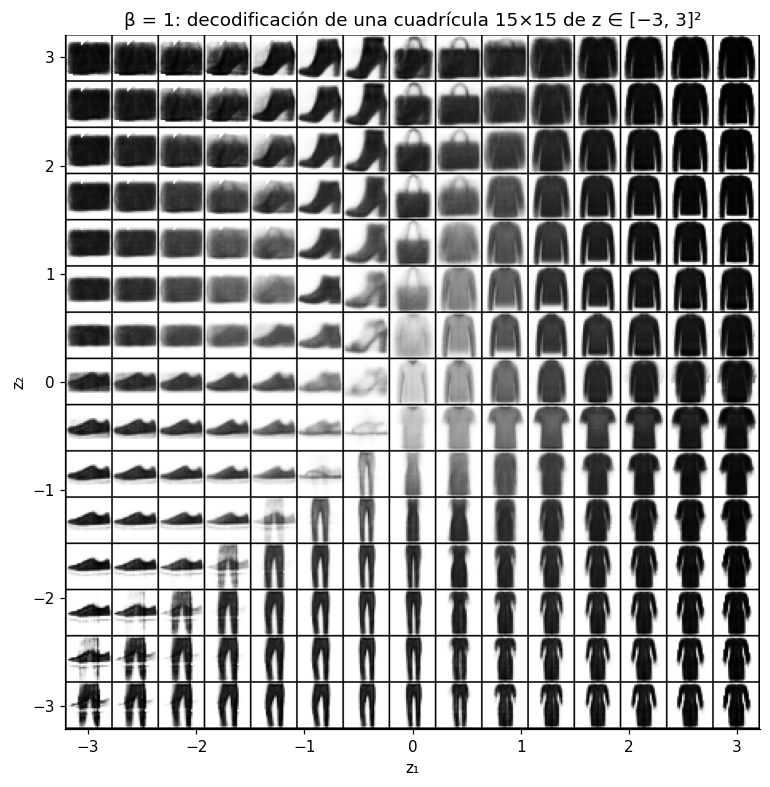

In [6]:
# (b) β = 1: imágenes decodificadas sobre una cuadrícula regular de 15×15 puntos de z en [−3, 3]²
G = 15
grid_vals = torch.linspace(-3, 3, G)
# filas: z₂ de +3 (arriba) a −3 (abajo); columnas: z₁ de −3 a +3
Z_grid = torch.stack([torch.stack([grid_vals[j], grid_vals[G - 1 - i]]) for i in range(G) for j in range(G)])
with torch.no_grad():
    grid_imgs = models[1.0].decode(Z_grid.to(device)).cpu()
plt.figure(figsize=(8.2, 8.2))
plt.imshow(tile(grid_imgs, G, G), cmap="gray_r", extent=(-3.21, 3.21, -3.21, 3.21))
plt.title("β = 1: decodificación de una cuadrícula 15×15 de z ∈ [−3, 3]²")
plt.xlabel("z₁"); plt.ylabel("z₂"); plt.grid(False)
savefig("t1_3b_cuadricula_beta1")

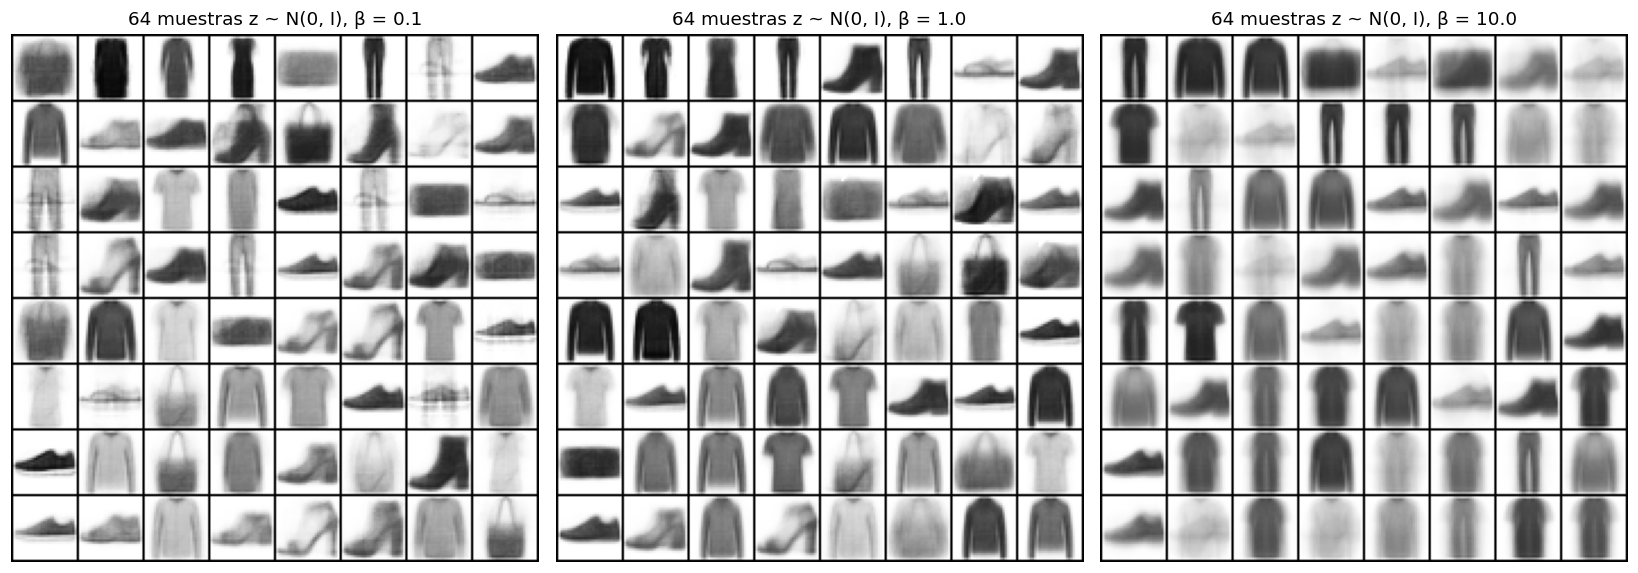

In [7]:
# (c) Para cada β, 64 imágenes generadas con z ~ N(0, I) (se usan los mismos 64 z para los tres modelos)
gen = torch.Generator().manual_seed(SEED)
Z64 = torch.randn(64, latent_dim, generator=gen)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
for ax, beta in zip(axes, beta_values):
    with torch.no_grad():
        imgs = models[beta].decode(Z64.to(device)).cpu()
    ax.imshow(tile(imgs, 8, 8), cmap="gray_r"); ax.set_title(f"64 muestras z ~ N(0, I), β = {beta}")
    ax.axis("off")
plt.tight_layout(); savefig("t1_3c_muestras_prior")

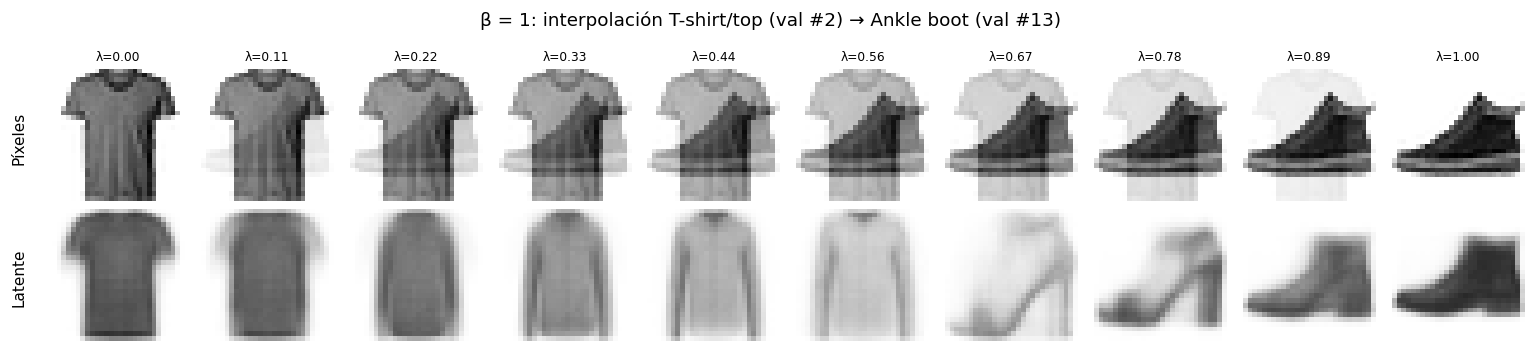

In [8]:
# (d) β = 1: interpolación entre dos imágenes de validación de clases distintas, 8 puntos intermedios
CLASS_A, CLASS_B = 0, 9                       # T-shirt/top → Ankle boot
# Regla de selección (reproducible): la primera imagen de validación de cada clase cuyo error de
# reconstrucción con β = 1 (decodificando μ) está por debajo de la mediana de su clase, para que los
# extremos sean ejemplos que el modelo representa bien y no casos atípicos.
with torch.no_grad():
    _rec_err = (models[1.0].decode(val_mu[1.0].to(device)).cpu() - X_val01).pow(2).sum(1)
def pick_index(k):
    idx = (Y_val == k).nonzero().flatten()
    med = _rec_err[idx].median()
    return int(idx[_rec_err[idx] < med][0])
idx_a, idx_b = pick_index(CLASS_A), pick_index(CLASS_B)
xa, xb_ = X_val01[idx_a], X_val01[idx_b]
lams = torch.linspace(0, 1, 10)                # extremos + 8 puntos intermedios
pix_interp = torch.stack([(1 - l) * xa + l * xb_ for l in lams])                  # espacio de píxeles
mu_a, mu_b = val_mu[1.0][idx_a], val_mu[1.0][idx_b]
z_interp = torch.stack([(1 - l) * mu_a + l * mu_b for l in lams])                 # espacio latente (sobre μ)
with torch.no_grad():
    lat_interp = models[1.0].decode(z_interp.to(device)).cpu()
fig, axes = plt.subplots(2, 10, figsize=(14, 3.3))
for k in range(10):
    axes[0, k].imshow(pix_interp[k].view(28, 28), cmap="gray_r", vmin=0, vmax=1)
    axes[1, k].imshow(lat_interp[k].view(28, 28), cmap="gray_r", vmin=0, vmax=1)
    axes[0, k].set_title(f"λ={lams[k]:.2f}", fontsize=8)
    for r in range(2): axes[r, k].axis("off")
axes[0, 0].text(-6, 14, "Píxeles", rotation=90, va="center", ha="right", fontsize=10)
axes[1, 0].text(-6, 14, "Latente", rotation=90, va="center", ha="right", fontsize=10)
plt.suptitle(f"β = 1: interpolación {CLASSES[CLASS_A]} (val #{idx_a}) → {CLASSES[CLASS_B]} (val #{idx_b})")
plt.tight_layout(); savefig("t1_3d_interpolacion")
RESULTS["interp"] = {"idx_a": idx_a, "idx_b": idx_b, "class_a": CLASSES[CLASS_A], "class_b": CLASSES[CLASS_B],
                     "mu_a": mu_a.tolist(), "mu_b": mu_b.tolist()}

## Task 1.4 — Análisis
### (a) Tabla final y KL en bits

In [9]:
LN2 = math.log(2.0)
rows = []
for beta in beta_values:
    rec, kl = histories[beta]["val_rec"][-1], histories[beta]["val_kl"][-1]
    rows.append({"β": beta, "Reconstrucción ‖x−x̂‖² (val)": rec, "KL (nats)": kl,
                 "KL (bits) = KL/ln2": kl / LN2, "bits clase log2(10)": math.log2(10)})
table_a = pd.DataFrame(rows)
print(table_a.round(3).to_string(index=False))

# KL por dimensión latente (¿alguna dimensión colapsó al prior?)
kl_per_dim = {}
for beta in beta_values:
    mu, lv = encode_mu_logvar(models[beta], X_val01)
    kl_per_dim[beta] = (0.5 * (mu.pow(2) + lv.exp() - lv - 1)).mean(0).tolist()
    print(f"β={beta}: KL por dimensión (nats) = {np.round(kl_per_dim[beta], 3)}")

# Información de clase que conserva μ: k-NN (k=15) entrenado con μ de 20 000 imágenes de train y evaluado en validación
@torch.no_grad()
def knn_acc(mu_tr, y_tr, mu_te, y_te, k=15):
    d = torch.cdist(mu_te, mu_tr)
    nn_idx = d.topk(k, largest=False).indices
    votes = y_tr[nn_idx]
    pred = torch.mode(votes, dim=1).values
    return (pred == y_te).float().mean().item()

knn = {}
for beta in beta_values:
    mu_tr = encode_mu_logvar(models[beta], X_train01[:20000])[0]
    knn[beta] = knn_acc(mu_tr, Y_train[:20000], val_mu[beta], Y_val)
    print(f"β={beta}: exactitud k-NN de la clase a partir de μ = {knn[beta]:.3f}")
RESULTS["table_a"] = rows; RESULTS["kl_per_dim"] = {str(b): v for b, v in kl_per_dim.items()}
RESULTS["knn_acc"] = {str(b): v for b, v in knn.items()}

   β  Reconstrucción ‖x−x̂‖² (val)  KL (nats)  KL (bits) = KL/ln2  bits clase log2(10)
 0.1                        20.134      8.535              12.314                3.322
 1.0                        21.288      5.149               7.428                3.322
10.0                        36.429      1.734               2.502                3.322
β=0.1: KL por dimensión (nats) = [4.292 4.243]
β=1.0: KL por dimensión (nats) = [2.615 2.533]
β=10.0: KL por dimensión (nats) = [0.968 0.766]
β=0.1: exactitud k-NN de la clase a partir de μ = 0.742
β=1.0: exactitud k-NN de la clase a partir de μ = 0.707
β=10.0: exactitud k-NN de la clase a partir de μ = 0.654


### (b) Verificación de la KL cerrada por Monte Carlo
Para una imagen de validación con el modelo β = 1: $\widehat{KL}=\frac1N\sum_{i=1}^N[\log q(z_i)-\log p(z_i)]$, $z_i\sim q(z\mid x)$, $N=10^5$.
Las log-densidades gaussianas se escriben a mano (sin `torch.distributions`).

In [10]:
def log_normal_diag(z, mu, logvar):
    """log N(z; μ, diag σ²) = Σ_j [ −½ log(2π) − ½ log σ_j² − (z_j − μ_j)² / (2 σ_j²) ]"""
    return (-0.5 * math.log(2 * math.pi) - 0.5 * logvar - (z - mu).pow(2) / (2 * logvar.exp())).sum(-1)

def log_std_normal(z):
    """log N(z; 0, I) = Σ_j [ −½ log(2π) − z_j² / 2 ]"""
    return (-0.5 * math.log(2 * math.pi) - 0.5 * z.pow(2)).sum(-1)

IDX_MC = 0
mu1, lv1 = encode_mu_logvar(models[1.0], X_val01[IDX_MC:IDX_MC + 1])
mu1, lv1 = mu1[0].double(), lv1[0].double()
kl_cf = (0.5 * (mu1.pow(2) + lv1.exp() - lv1 - 1)).sum().item()          # forma cerrada
N_MC = 100_000
g = torch.Generator().manual_seed(SEED)
eps = torch.randn(N_MC, latent_dim, generator=g, dtype=torch.float64)
z = mu1 + torch.exp(0.5 * lv1) * eps                                       # muestras de q(z|x)
log_ratio = log_normal_diag(z, mu1, lv1) - log_std_normal(z)               # log q(z) − log p(z)
kl_mc = log_ratio.mean().item()
se_mc = (log_ratio.std(unbiased=True) / math.sqrt(N_MC)).item()           # error estándar MC
rel_err = abs(kl_mc - kl_cf) / kl_cf
print(f"Imagen val #{IDX_MC} ({CLASSES[int(Y_val[IDX_MC])]}): μ = {mu1.numpy().round(4)}, σ = {torch.exp(0.5 * lv1).numpy().round(4)}")
print(f"KL cerrada = {kl_cf:.5f} nats | KL Monte Carlo = {kl_mc:.5f} nats | error rel. = {100 * rel_err:.4f}%")
print(f"Desv. est. de log q − log p = {log_ratio.std().item():.4f} → error estándar = {se_mc:.5f} nats "
      f"({100 * se_mc / kl_cf:.4f}% relativo); |MC − cerrada| = {abs(kl_mc - kl_cf) / se_mc:.2f} errores estándar")
RESULTS["mc_kl"] = {"idx": IDX_MC, "class": CLASSES[int(Y_val[IDX_MC])], "mu": mu1.tolist(),
                    "sigma": torch.exp(0.5 * lv1).tolist(), "kl_closed": kl_cf, "kl_mc": kl_mc,
                    "rel_err": rel_err, "std_log_ratio": log_ratio.std().item(), "se": se_mc,
                    "z_score": abs(kl_mc - kl_cf) / se_mc, "N": N_MC}

Imagen val #0 (T-shirt/top): μ = [1.7327 0.205 ], σ = [0.1556 0.0797]
KL cerrada = 4.92736 nats | KL Monte Carlo = 4.92343 nats | error rel. = 0.0798%
Desv. est. de log q − log p = 1.0261 → error estándar = 0.00324 nats (0.0659% relativo); |MC − cerrada| = 1.21 errores estándar


### (c) Regiones no reconocibles de la cuadrícula e interpolaciones
Dos medidas para cada imagen decodificada x̂ de la cuadrícula (β = 1):
1. **Distancia a la imagen real más cercana** (L2 en píxeles, contra las 55 000 de entrenamiento). Una x̂ lejos
   de toda imagen real está fuera de la variedad de los datos. Umbral: percentil 95 de esa misma distancia para
   reconstrucciones de 1 000 imágenes de validación (decodificando su μ), es decir, lo "normal" para el decoder.
2. **Confianza** max_c p(c | x̂) de un clasificador auxiliar (MLP pequeño sobre imágenes reales en [0,1]):
   baja confianza = imagen ambigua entre clases.

Clasificador auxiliar: exactitud en validación = 0.874


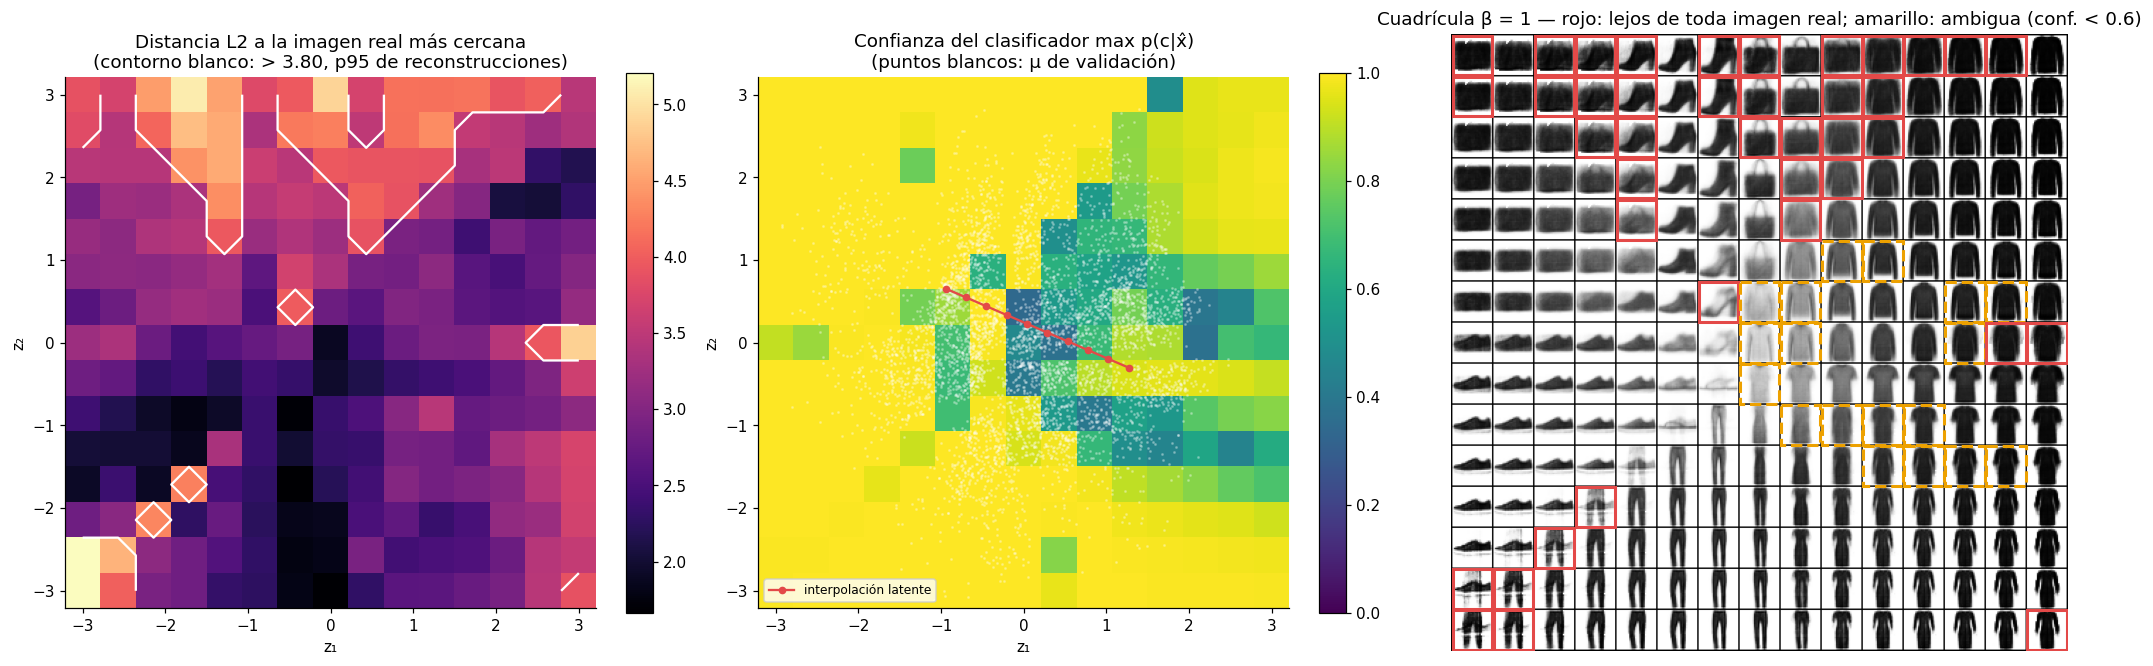

Umbral 'lejos' (p95 de reconstrucciones) = 3.798; mediana reconstrucciones = 2.636
Celdas lejos de toda imagen real: 40 de 225; ambiguas (conf<0.6, no lejanas): 18
‖z‖ medio: lejanas = 2.93 | ambiguas = 1.48 | resto = 2.45
Distancia media a la imagen real más cercana: ‖z‖ > 3 → 3.33; ‖z‖ ≤ 1.5 → 2.70
Confianza media: ‖z‖ > 3 → 0.962; ‖z‖ ≤ 1.5 → 0.768
Fracción de μ de validación con ‖μ‖ > 2.5: 0.0320; masa del prior con ‖z‖ > 3: 0.0111
  esquina sup. izq.: celdas lejanas 7/16, dist. media 3.79
  esquina inf. izq.: celdas lejanas 6/16, dist. media 3.36
  esquina sup. der.: celdas lejanas 3/16, dist. media 3.12
  esquina inf. der.: celdas lejanas 1/16, dist. media 3.19
   λ píxeles: clase  píxeles: conf latente: clase  latente: conf
0.00    T-shirt/top          0.982    T-shirt/top          0.864
0.11    T-shirt/top          0.955          Shirt          0.478
0.22    T-shirt/top          0.883           Coat          0.525
0.33    T-shirt/top          0.720           Coat          0.443

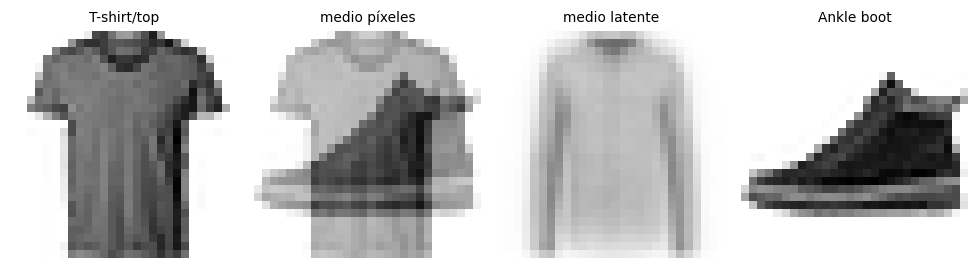

In [11]:
torch.manual_seed(SEED)
clf = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)).to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=1e-3)
for ep in range(5):
    perm = torch.randperm(len(X_train01))
    for i in range(0, len(X_train01), 256):
        b = perm[i:i + 256]
        loss = nn.functional.cross_entropy(clf(X_train01[b].to(device)), Y_train[b].to(device))
        opt_c.zero_grad(); loss.backward(); opt_c.step()
with torch.no_grad():
    clf_acc = (clf(X_val01.to(device)).argmax(1).cpu() == Y_val).float().mean().item()
print(f"Clasificador auxiliar: exactitud en validación = {clf_acc:.3f}")

with torch.no_grad():
    p_grid = torch.softmax(clf(grid_imgs.to(device)), 1).cpu()
conf_grid = p_grid.max(1).values.view(G, G).numpy()           # fila 0 = z₂ = +3
radius_grid = Z_grid.norm(dim=1).view(G, G).numpy()

@torch.no_grad()
def nn_dist_to_train(imgs, bs=250):
    """Distancia L2 de cada imagen a la imagen de entrenamiento más cercana."""
    out = []
    for i in range(0, len(imgs), bs):
        out.append(torch.cdist(imgs[i:i + bs], X_train01).min(1).values)
    return torch.cat(out)

nnd_grid = nn_dist_to_train(grid_imgs).view(G, G).numpy()
with torch.no_grad():
    recon_ref = models[1.0].decode(val_mu[1.0][:1000].to(device)).cpu()
nnd_ref = nn_dist_to_train(recon_ref)
thr_far = float(nnd_ref.quantile(0.95))
far = nnd_grid > thr_far                                     # fuera de la variedad de datos reales
amb = conf_grid < 0.6                                        # ambiguas entre clases

fig, axes = plt.subplots(1, 3, figsize=(19, 6.2), gridspec_kw={"width_ratios": [1, 1, 1.05]})
ext = (-3.21, 3.21, -3.21, 3.21)
im0 = axes[0].imshow(nnd_grid, cmap="magma", extent=ext)
axes[0].contour(np.linspace(-3, 3, G), np.linspace(3, -3, G), far.astype(float), levels=[0.5], colors="white", linewidths=1.5)
axes[0].set_title(f"Distancia L2 a la imagen real más cercana\n(contorno blanco: > {thr_far:.2f}, p95 de reconstrucciones)")
plt.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(conf_grid, cmap="viridis", vmin=0, vmax=1, extent=ext)
axes[1].scatter(val_mu[1.0][:, 0], val_mu[1.0][:, 1], s=1, c="white", alpha=0.25)
axes[1].plot(z_interp[:, 0], z_interp[:, 1], "-o", color="#e34948", ms=4, lw=1.5, label="interpolación latente")
axes[1].set_title("Confianza del clasificador max p(c|x̂)\n(puntos blancos: μ de validación)")
axes[1].legend(loc="lower left", fontsize=8)
plt.colorbar(im1, ax=axes[1], fraction=0.046)
for ax in axes[:2]:
    ax.set_xlim(-3.21, 3.21); ax.set_ylim(-3.21, 3.21); ax.set_xlabel("z₁"); ax.set_ylabel("z₂"); ax.grid(False)
axes[2].imshow(tile(grid_imgs, G, G), cmap="gray_r"); axes[2].axis("off")
for i in range(G):
    for j in range(G):
        x0_, y0_ = 1 + j * 29 - 0.5, 1 + i * 29 - 0.5
        if far[i, j]:
            axes[2].add_patch(Rectangle((x0_, y0_), 28, 28, fill=False, ec="#e34948", lw=2))
        elif amb[i, j]:
            axes[2].add_patch(Rectangle((x0_, y0_), 28, 28, fill=False, ec="#eda100", lw=2, ls="--"))
axes[2].set_title("Cuadrícula β = 1 — rojo: lejos de toda imagen real; amarillo: ambigua (conf. < 0.6)")
plt.tight_layout(); savefig("t1_4c_regiones_cuadricula")

print(f"Umbral 'lejos' (p95 de reconstrucciones) = {thr_far:.3f}; mediana reconstrucciones = {nnd_ref.median():.3f}")
print(f"Celdas lejos de toda imagen real: {far.sum()} de {G * G}; ambiguas (conf<0.6, no lejanas): {(amb & ~far).sum()}")
print(f"‖z‖ medio: lejanas = {radius_grid[far].mean():.2f} | ambiguas = {radius_grid[amb & ~far].mean():.2f} | "
      f"resto = {radius_grid[~far & ~amb].mean():.2f}")
corner = radius_grid > 3.0
print(f"Distancia media a la imagen real más cercana: ‖z‖ > 3 → {nnd_grid[corner].mean():.2f}; ‖z‖ ≤ 1.5 → {nnd_grid[radius_grid <= 1.5].mean():.2f}")
print(f"Confianza media: ‖z‖ > 3 → {conf_grid[corner].mean():.3f}; ‖z‖ ≤ 1.5 → {conf_grid[radius_grid <= 1.5].mean():.3f}")
print(f"Fracción de μ de validación con ‖μ‖ > 2.5: {(val_mu[1.0].norm(dim=1) > 2.5).float().mean().item():.4f}; "
      f"masa del prior con ‖z‖ > 3: {math.exp(-4.5):.4f}")
for name, mask in [("esquina sup. izq.", (np.arange(G)[:, None] < 4) & (np.arange(G)[None, :] < 4)),
                   ("esquina inf. izq.", (np.arange(G)[:, None] > 10) & (np.arange(G)[None, :] < 4)),
                   ("esquina sup. der.", (np.arange(G)[:, None] < 4) & (np.arange(G)[None, :] > 10)),
                   ("esquina inf. der.", (np.arange(G)[:, None] > 10) & (np.arange(G)[None, :] > 10))]:
    print(f"  {name}: celdas lejanas {far[mask].sum()}/{mask.sum()}, dist. media {nnd_grid[mask].mean():.2f}")

with torch.no_grad():
    p_pix = torch.softmax(clf(pix_interp.to(device)), 1).cpu()
    p_lat = torch.softmax(clf(lat_interp.to(device)), 1).cpu()
interp_tab = pd.DataFrame({
    "λ": lams.numpy().round(2),
    "píxeles: clase": [CLASSES[k] for k in p_pix.argmax(1)], "píxeles: conf": p_pix.max(1).values.numpy().round(3),
    "latente: clase": [CLASSES[k] for k in p_lat.argmax(1)], "latente: conf": p_lat.max(1).values.numpy().round(3)})
print(interp_tab.to_string(index=False))

# Comparación de los puntos medios (λ ≈ 0.5: promedio de los índices 4 y 5)
mid_pix = 0.5 * (xa + xb_)
with torch.no_grad():
    mid_lat = models[1.0].decode((0.5 * (mu_a + mu_b)).view(1, -1).to(device)).cpu()[0]
    p_mid_pix = torch.softmax(clf(mid_pix.view(1, -1).to(device)), 1).cpu()[0]
    p_mid_lat = torch.softmax(clf(mid_lat.view(1, -1).to(device)), 1).cpu()[0]
    rec_mid = models[1.0].decode(encode_mu_logvar(models[1.0], mid_pix.view(1, -1))[0].to(device)).cpu()[0]
print(f"Punto medio en píxeles: clase {CLASSES[int(p_mid_pix.argmax())]} conf {p_mid_pix.max():.3f}; "
      f"píxeles con valor intermedio 0.2–0.6: {((mid_pix > 0.2) & (mid_pix < 0.6)).float().mean():.3f}")
print(f"Punto medio en latente: clase {CLASSES[int(p_mid_lat.argmax())]} conf {p_mid_lat.max():.3f}; "
      f"z_mid = {(0.5 * (mu_a + mu_b)).numpy().round(3)}")
fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, im_, t in zip(axes, [xa, mid_pix, mid_lat, xb_],
                      [CLASSES[CLASS_A], "medio píxeles", "medio latente", CLASSES[CLASS_B]]):
    ax.imshow(im_.view(28, 28), cmap="gray_r", vmin=0, vmax=1); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); savefig("t1_4c_puntos_medios")
RESULTS["clf_acc"] = clf_acc
RESULTS["grid"] = {"thr_far": thr_far, "n_far": int(far.sum()), "n_amb": int((amb & ~far).sum()),
                   "radius_far": float(radius_grid[far].mean()), "radius_amb": float(radius_grid[amb & ~far].mean()),
                   "radius_ok": float(radius_grid[~far & ~amb].mean()),
                   "nnd_corner": float(nnd_grid[corner].mean()), "nnd_center": float(nnd_grid[radius_grid <= 1.5].mean()),
                   "conf_corner": float(conf_grid[corner].mean()), "conf_center": float(conf_grid[radius_grid <= 1.5].mean()),
                   "frac_mu_r_gt_2p5": float((val_mu[1.0].norm(dim=1) > 2.5).float().mean())}
RESULTS["interp_table"] = interp_tab.to_dict(orient="list")
RESULTS["midpoints"] = {"pix_class": CLASSES[int(p_mid_pix.argmax())], "pix_conf": float(p_mid_pix.max()),
                        "lat_class": CLASSES[int(p_mid_lat.argmax())], "lat_conf": float(p_mid_lat.max()),
                        "z_mid": (0.5 * (mu_a + mu_b)).tolist()}

### (d) Nitidez de imágenes reales y generadas
Nitidez = magnitud media de la diferencia entre píxeles horizontalmente adyacentes, $\frac{1}{N\cdot28\cdot27}\sum|x_{r,c+1}-x_{r,c}|$.

In [12]:
def sharpness(imgs):
    imgs = imgs.view(-1, 28, 28)
    return (imgs[:, :, 1:] - imgs[:, :, :-1]).abs().mean().item()

sharp = {"Reales (val)": sharpness(X_val01[:1000])}
g = torch.Generator().manual_seed(SEED + 1)
Z1000 = torch.randn(1000, latent_dim, generator=g)
for beta in beta_values:
    with torch.no_grad():
        sharp[f"Generadas β = {beta}"] = sharpness(models[beta].decode(Z1000.to(device)).cpu())
for k, v in sharp.items(): print(f"{k:22s}: {v:.4f}")
# Referencia adicional: reconstrucciones de las mismas 1 000 imágenes reales con β=1 (usando μ)
with torch.no_grad():
    rec_sharp = sharpness(models[1.0].decode(val_mu[1.0][:1000].to(device)).cpu())
print(f"{'Reconstrucciones β=1':22s}: {rec_sharp:.4f}")
RESULTS["sharpness"] = sharp; RESULTS["sharpness_recon_beta1"] = rec_sharp
for beta in beta_values:
    RESULTS.setdefault("sigma2_x", {})[str(beta)] = beta / 2

Reales (val)          : 0.0891
Generadas β = 0.1     : 0.0432
Generadas β = 1.0     : 0.0489
Generadas β = 10.0    : 0.0436
Reconstrucciones β=1  : 0.0541


## Task 2 — Proceso forward de difusión
A partir de aquí los datos se escalan a **[−1, 1]** ($x\mapsto 2x-1$), con la misma partición entrenamiento/validación.

### Task 2.1 — Calendario lineal y fórmula cerrada
Diapositiva *Difusión, parte 1*: $q(x_t\mid x_{t-1})=\mathcal N(\sqrt{1-\beta_t}\,x_{t-1},\beta_t I)$, $\alpha_t=1-\beta_t$,
$\bar\alpha_t=\prod_{s=1}^t\alpha_s$ y $x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon$.

In [13]:
X_train_pm = X_train01 * 2 - 1          # [0,1] → [−1,1]
X_val_pm = X_val01 * 2 - 1

T = 1000
beta_start = 1e-4
beta_end = 0.02

def linear_schedule(T, beta_start, beta_end):
    """β_t lineal para t = 1..T. Se devuelven tensores de largo T+1 con la posición 0 como relleno
    (β_0 = 0, ᾱ_0 = 1) para poder indexar directamente con t."""
    betas = torch.zeros(T + 1, dtype=torch.float64)
    betas[1:] = beta_start + (beta_end - beta_start) * torch.arange(T, dtype=torch.float64) / (T - 1)
    alphas = 1.0 - betas                          # α_t = 1 − β_t
    alpha_bar = torch.cumprod(alphas, dim=0)      # ᾱ_t = Π_{s≤t} α_s  (ᾱ_0 = 1)
    return betas, alphas, alpha_bar

betas, alphas, alpha_bar = linear_schedule(T, beta_start, beta_end)
print(f"β_1 = {betas[1]:.6f}, β_T = {betas[T]:.6f}, ᾱ_T = {alpha_bar[T]:.6e}")

def q_sample(x0, t, eps, alpha_bar=alpha_bar):
    """Fórmula cerrada del forward: x_t = √ᾱ_t · x_0 + √(1 − ᾱ_t) · ε.
    x0: (B, ...) lote; t: (B,) enteros en 1..T; eps: ruido ~ N(0, I) con la forma de x0."""
    ab = alpha_bar.to(x0.dtype)[t].view(-1, *([1] * (x0.dim() - 1)))   # broadcasting por imagen
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

# ejemplo de uso
t_demo = torch.tensor([1, 500, 1000]); x_demo = X_val_pm[:3]
print("shapes:", tuple(q_sample(x_demo, t_demo, torch.randn_like(x_demo)).shape))
RESULTS["linear"] = {"beta1": betas[1].item(), "betaT": betas[T].item(), "abar_T": alpha_bar[T].item()}

β_1 = 0.000100, β_T = 0.020000, ᾱ_T = 4.035830e-05
shapes: (3, 784)


### Task 2.2 — Verificación empírica de la fórmula cerrada
Se aplica el proceso paso a paso $x_s=\sqrt{\alpha_s}\,x_{s-1}+\sqrt{\beta_s}\,\epsilon_s$ a 5 000 copias de la misma imagen durante 300 pasos.

ᾱ_300 = 0.396420 → √ᾱ_300 = 0.629619, 1 − ᾱ_300 = 0.603580
Error máximo absoluto de la media = 0.03396
Varianza empírica promedio = 0.603723 vs teórica 0.603580 (dif. relativa 0.024%), rango [0.5758, 0.6412]
Error estándar de la media: √((1−ᾱ)/N) = 0.01099
Error máximo en unidades de EE = 3.09; fracción de píxeles con |err| < 1.96·EE = 0.9592
Máximo de 784 |N(0,1)|: mediana 3.32, percentiles 5–95 = [2.89, 3.99]
EE aproximado de la varianza promedio (784 píxeles): 0.000431; desviación observada = 0.33 EE


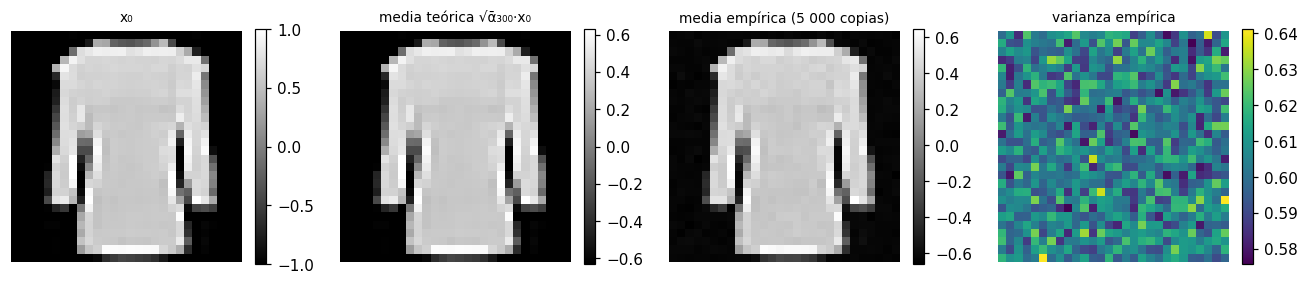

In [14]:
torch.manual_seed(SEED)
IDX_X0 = 0
x0 = X_val_pm[IDX_X0].double()                     # imagen fija (val #0)
NCOP, TS = 5000, 300
x = x0.repeat(NCOP, 1)                             # 5 000 copias
for s in range(1, TS + 1):
    eps_s = torch.randn_like(x)                    # ruido independiente en cada paso y copia
    x = alphas[s].sqrt() * x + betas[s].sqrt() * eps_s
emp_mean = x.mean(0); emp_var = x.var(0, unbiased=True)
th_mean = alpha_bar[TS].sqrt() * x0                 # √ᾱ_300 · x_0
th_var = 1 - alpha_bar[TS]                          # 1 − ᾱ_300
err_mean = (emp_mean - th_mean).abs()
se_mean = math.sqrt(th_var / NCOP)                  # error estándar de un promedio de 5 000 muestras
print(f"ᾱ_300 = {alpha_bar[TS]:.6f} → √ᾱ_300 = {alpha_bar[TS].sqrt():.6f}, 1 − ᾱ_300 = {th_var:.6f}")
print(f"Error máximo absoluto de la media = {err_mean.max():.5f}")
print(f"Varianza empírica promedio = {emp_var.mean():.6f} vs teórica {th_var:.6f} "
      f"(dif. relativa {100 * (emp_var.mean() - th_var) / th_var:.3f}%), rango [{emp_var.min():.4f}, {emp_var.max():.4f}]")
print(f"Error estándar de la media: √((1−ᾱ)/N) = {se_mean:.5f}")
print(f"Error máximo en unidades de EE = {err_mean.max() / se_mean:.2f}; "
      f"fracción de píxeles con |err| < 1.96·EE = {(err_mean < 1.96 * se_mean).double().mean():.4f}")
# Máximo esperado de 784 errores |N(0, EE²)| independientes (simulación de referencia)
gm = torch.Generator().manual_seed(SEED)
ref_max = torch.randn(20000, 784, generator=gm).abs().max(1).values
print(f"Máximo de 784 |N(0,1)|: mediana {ref_max.median():.2f}, percentiles 5–95 = "
      f"[{ref_max.quantile(0.05):.2f}, {ref_max.quantile(0.95):.2f}]")
se_var_avg = math.sqrt(2 * th_var ** 2 / (NCOP - 1) / 784)
print(f"EE aproximado de la varianza promedio (784 píxeles): {se_var_avg:.6f}; "
      f"desviación observada = {(emp_var.mean() - th_var) / se_var_avg:.2f} EE")
RESULTS["t22"] = {"idx": IDX_X0, "class": CLASSES[int(Y_val[IDX_X0])], "abar_300": alpha_bar[TS].item(),
                  "sqrt_abar_300": alpha_bar[TS].sqrt().item(), "th_var": th_var.item(),
                  "max_err_mean": err_mean.max().item(), "mean_err_mean": err_mean.mean().item(),
                  "emp_var_mean": emp_var.mean().item(), "emp_var_min": emp_var.min().item(),
                  "emp_var_max": emp_var.max().item(), "se_mean": se_mean,
                  "max_err_in_se": (err_mean.max() / se_mean).item(),
                  "frac_within_196": (err_mean < 1.96 * se_mean).double().mean().item(),
                  "ref_max_median": ref_max.median().item(), "ref_max_p05": ref_max.quantile(0.05).item(),
                  "ref_max_p95": ref_max.quantile(0.95).item(), "se_var_avg": se_var_avg,
                  "var_dev_in_se": ((emp_var.mean() - th_var) / se_var_avg).item()}

fig, axes = plt.subplots(1, 4, figsize=(12, 3.1))
for ax, im_, t_ in zip(axes, [x0, th_mean, emp_mean, emp_var],
                       ["x₀", "media teórica √ᾱ₃₀₀·x₀", "media empírica (5 000 copias)", "varianza empírica"]):
    h = ax.imshow(im_.view(28, 28).numpy(), cmap="gray" if "var" not in t_ else "viridis")
    ax.set_title(t_, fontsize=9); ax.axis("off"); plt.colorbar(h, ax=ax, fraction=0.046)
plt.tight_layout(); savefig("t2_2_verificacion")

### Task 2.3 — Visualización y SNR

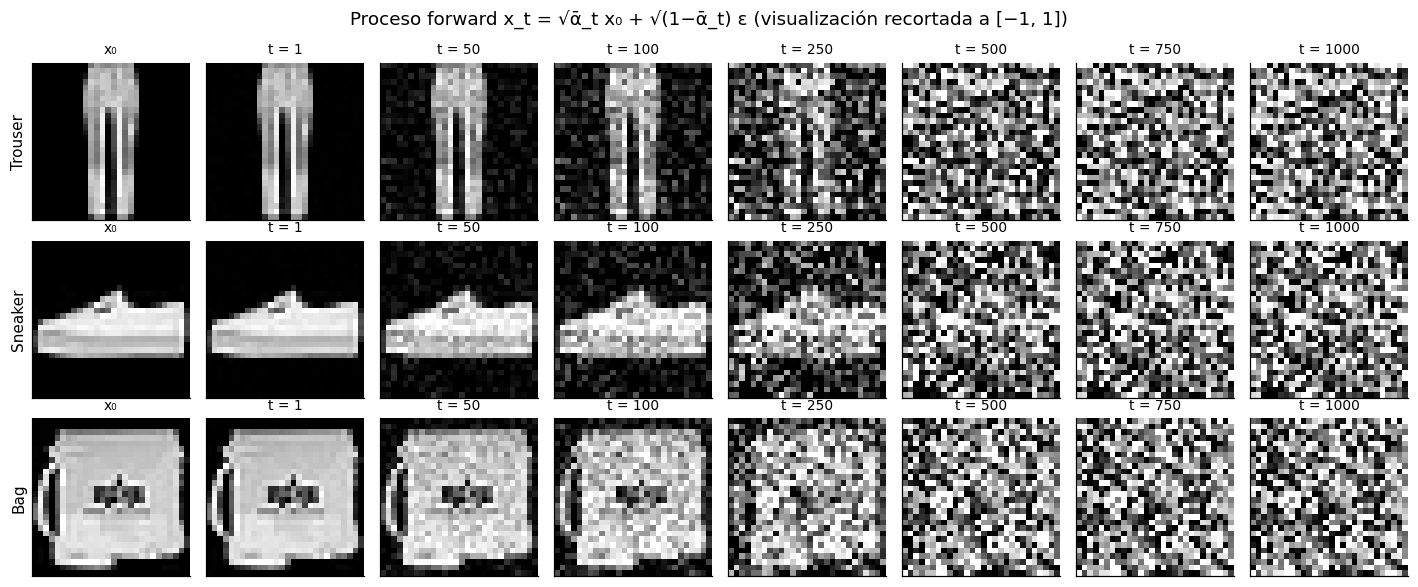

In [15]:
SHOW_T = [1, 50, 100, 250, 500, 750, 1000]
SHOW_CLASSES = [1, 7, 8]                     # Trouser, Sneaker, Bag
torch.manual_seed(SEED)
fig, axes = plt.subplots(3, len(SHOW_T) + 1, figsize=(13, 5.4))
for r, k in enumerate(SHOW_CLASSES):
    i0 = int((Y_val == k).nonzero()[0]); xk = X_val_pm[i0]
    eps_k = torch.randn_like(xk)             # mismo ε para todos los t de una imagen
    axes[r, 0].imshow(xk.view(28, 28), cmap="gray", vmin=-1, vmax=1); axes[r, 0].set_title("x₀", fontsize=9)
    axes[r, 0].set_ylabel(CLASSES[k])
    for c, t_ in enumerate(SHOW_T):
        xt = q_sample(xk.view(1, -1).double(), torch.tensor([t_]), eps_k.view(1, -1).double())
        axes[r, c + 1].imshow(xt.view(28, 28).clamp(-1, 1), cmap="gray", vmin=-1, vmax=1)
        axes[r, c + 1].set_title(f"t = {t_}", fontsize=9)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("Proceso forward x_t = √ᾱ_t x₀ + √(1−ᾱ_t) ε (visualización recortada a [−1, 1])")
plt.tight_layout(); savefig("t2_3a_forward")

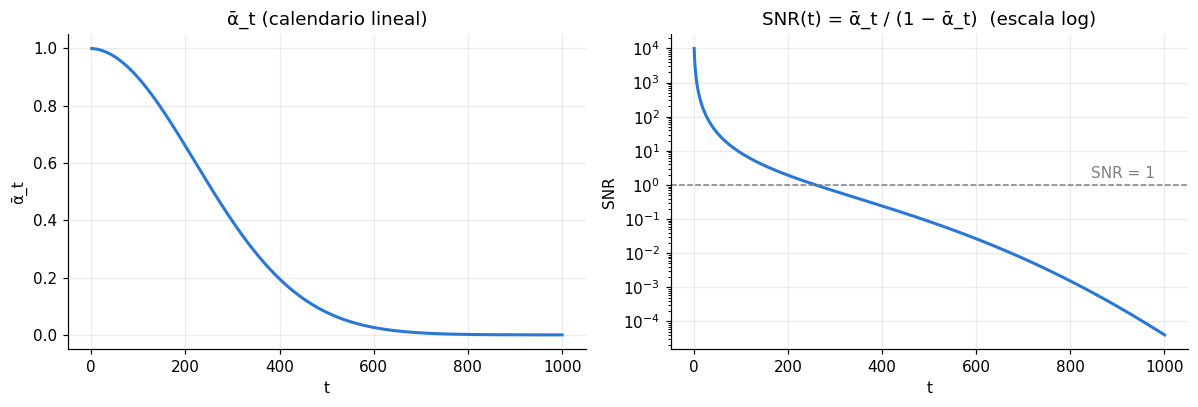

Primer t con SNR(t) < 1: 260  (ᾱ = 0.4976)
Primer t con ᾱ_t < 0.01: 674  (ᾱ = 0.00999)


In [16]:
def snr(alpha_bar):
    """SNR(t) = ᾱ_t / (1 − ᾱ_t), t = 1..T"""
    return alpha_bar[1:] / (1 - alpha_bar[1:])

t_axis = np.arange(1, T + 1)
snr_lin = snr(alpha_bar)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t_axis, alpha_bar[1:], color=BETA_COLORS[0], lw=2)
axes[0].set_title("ᾱ_t (calendario lineal)"); axes[0].set_xlabel("t"); axes[0].set_ylabel("ᾱ_t")
axes[1].semilogy(t_axis, snr_lin, color=BETA_COLORS[0], lw=2)
axes[1].axhline(1, color="gray", ls="--", lw=1); axes[1].text(980, 1.6, "SNR = 1", ha="right", color="gray")
axes[1].set_title("SNR(t) = ᾱ_t / (1 − ᾱ_t)  (escala log)"); axes[1].set_xlabel("t"); axes[1].set_ylabel("SNR")
plt.tight_layout(); savefig("t2_3b_abar_snr")

def first_t(cond):
    idx = torch.nonzero(cond)
    return int(idx[0]) + 1 if len(idx) else None   # +1 porque cond está indexado desde t = 1

t_snr1_lin = first_t(snr_lin < 1)
t_ab001_lin = first_t(alpha_bar[1:] < 0.01)
print(f"Primer t con SNR(t) < 1: {t_snr1_lin}  (ᾱ = {alpha_bar[t_snr1_lin]:.4f})")
print(f"Primer t con ᾱ_t < 0.01: {t_ab001_lin}  (ᾱ = {alpha_bar[t_ab001_lin]:.5f})")
RESULTS["t23"] = {"t_snr1": t_snr1_lin, "t_ab001": t_ab001_lin,
                  "abar_at": {str(t_): alpha_bar[t_].item() for t_ in SHOW_T},
                  "snr_at": {str(t_): snr_lin[t_ - 1].item() for t_ in SHOW_T}}

### Task 2.4 — Calendario propio: coseno modificado
Se parte del calendario coseno de Nichol & Dhariwal (2021), *Improved Denoising Diffusion Probabilistic Models*:
$\bar\alpha_t=f(t)/f(0)$, $f(t)=\cos^2\!\left(\frac{t/T+s}{1+s}\cdot\frac{\pi}{2}\right)$, $s=0.008$, con
$\beta_t=1-\bar\alpha_t/\bar\alpha_{t-1}$ recortado a 0.999.

**Modificación:** el recorte se baja de 0.999 a 0.5. Con el original, el último paso tiene $\beta_T=0.999$
(destruye casi toda la señal restante en un solo paso y hace $1/\sqrt{\alpha_T}\approx 31.6$ en el muestreo).
Con 0.5, $\beta_t\in(0,1)$ para todo $t$, ningún paso individual es extremo y aun así $\bar\alpha_T<10^{-3}$.

Coseno modificado: β_1 = 4.13e-05, β_T = 0.500, pasos recortados = 3
                       ᾱ_T    primer t SNR<1
Lineal           4.036e-05               260
Coseno mod.      2.732e-06               497


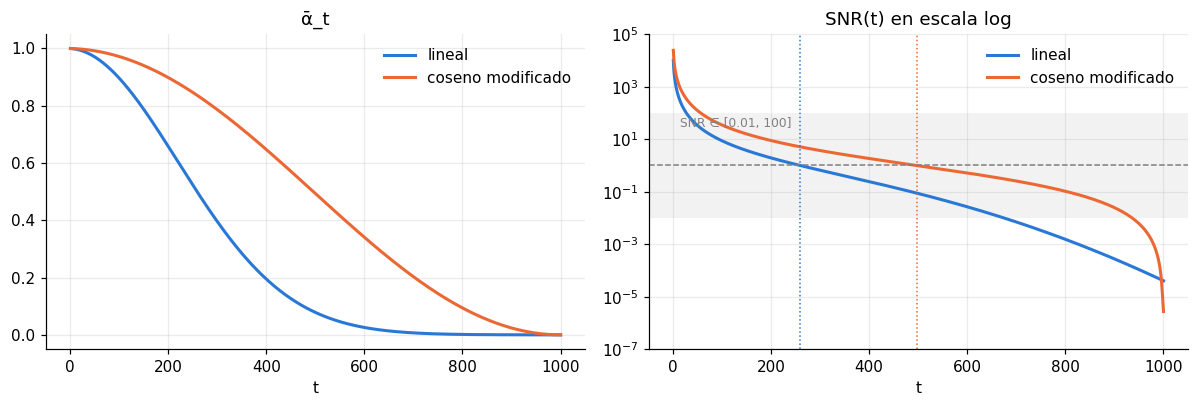

In [17]:
def cosine_mod_schedule(T, s=0.008, beta_max=0.5):
    t = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((t / T + s) / (1 + s)) * math.pi / 2) ** 2
    ab_raw = f / f[0]                                          # ᾱ_t del coseno original
    betas_c = torch.zeros(T + 1, dtype=torch.float64)
    betas_c[1:] = (1 - ab_raw[1:] / ab_raw[:-1]).clamp(max=beta_max)   # β_t = 1 − ᾱ_t/ᾱ_{t−1}, recortado
    alphas_c = 1 - betas_c
    alpha_bar_c = torch.cumprod(alphas_c, 0)                   # ᾱ recalculado con los β recortados
    return betas_c, alphas_c, alpha_bar_c

betas_c, alphas_c, alpha_bar_c = cosine_mod_schedule(T)
assert (betas_c[1:] > 0).all() and (betas_c[1:] < 1).all() and alpha_bar_c[T] < 1e-3
snr_cos = snr(alpha_bar_c)
t_snr1_cos = first_t(snr_cos < 1)
n_clipped = int((betas_c[1:] >= 0.5 - 1e-12).sum())
print(f"Coseno modificado: β_1 = {betas_c[1]:.2e}, β_T = {betas_c[T]:.3f}, pasos recortados = {n_clipped}")
print(f"{'':12s}{'ᾱ_T':>14s}{'primer t SNR<1':>18s}")
print(f"{'Lineal':12s}{alpha_bar[T].item():14.3e}{t_snr1_lin:18d}")
print(f"{'Coseno mod.':12s}{alpha_bar_c[T].item():14.3e}{t_snr1_cos:18d}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(t_axis, alpha_bar[1:], color=BETA_COLORS[0], lw=2, label="lineal")
axes[0].plot(t_axis, alpha_bar_c[1:], color=BETA_COLORS[1], lw=2, label="coseno modificado")
axes[0].set_title("ᾱ_t"); axes[0].set_xlabel("t"); axes[0].legend(frameon=False)
axes[1].semilogy(t_axis, snr_lin, color=BETA_COLORS[0], lw=2, label="lineal")
axes[1].semilogy(t_axis, snr_cos, color=BETA_COLORS[1], lw=2, label="coseno modificado")
axes[1].axhline(1, color="gray", ls="--", lw=1)
for v, c in [(t_snr1_lin, BETA_COLORS[0]), (t_snr1_cos, BETA_COLORS[1])]:
    axes[1].axvline(v, color=c, ls=":", lw=1)
axes[1].axhspan(0.01, 100, color="gray", alpha=0.10, lw=0)
axes[1].text(15, 30, "SNR ∈ [0.01, 100]", color="gray", fontsize=8)
axes[1].set_ylim(1e-7, 1e5)
axes[1].set_title("SNR(t) en escala log"); axes[1].set_xlabel("t"); axes[1].legend(frameon=False)
plt.tight_layout(); savefig("t2_4_snr_calendarios")
RESULTS["t24"] = {"abar_T_lin": alpha_bar[T].item(), "abar_T_cos": alpha_bar_c[T].item(),
                  "t_snr1_lin": t_snr1_lin, "t_snr1_cos": t_snr1_cos, "beta1_cos": betas_c[1].item(),
                  "betaT_cos": betas_c[T].item(), "n_clipped": n_clipped}

### Task 2.5 — Preguntas
**(a)** Aproximación $\log\bar\alpha_T\approx-\sum_t\beta_t-\tfrac12\sum_t\beta_t^2$ (cálculo a mano en el documento; aquí se verifica).

In [18]:
sum_b = betas[1:].sum().item(); sum_b2 = betas[1:].pow(2).sum().item()
hand_sum_b = T * (beta_start + beta_end) / 2                                     # suma aritmética
hand_sum_b2 = T * (beta_start ** 2 + beta_start * beta_end + beta_end ** 2) / 3   # integral de β(t)² lineal
log_ab_approx = -hand_sum_b - 0.5 * hand_sum_b2
print(f"Σβ_t: a mano = {hand_sum_b:.4f}, numérico = {sum_b:.4f}")
print(f"Σβ_t²: aprox. integral = {hand_sum_b2:.5f}, numérico = {sum_b2:.5f}")
print(f"log ᾱ_T ≈ {log_ab_approx:.4f} → ᾱ_T ≈ {math.exp(log_ab_approx):.4e}")
print(f"Numérico: log ᾱ_T = {math.log(alpha_bar[T]):.4f}, ᾱ_T = {alpha_bar[T]:.4e}, "
      f"error relativo = {100 * abs(math.exp(log_ab_approx) - alpha_bar[T].item()) / alpha_bar[T].item():.2f}%")
sum_b3 = betas[1:].pow(3).sum().item()
print(f"Término siguiente de la serie −⅓Σβ³ = {-sum_b3 / 3:.5f}")
RESULTS["t25a"] = {"hand_sum_b": hand_sum_b, "sum_b": sum_b, "hand_sum_b2": hand_sum_b2, "sum_b2": sum_b2,
                   "log_ab_approx": log_ab_approx, "ab_approx": math.exp(log_ab_approx),
                   "log_ab_num": math.log(alpha_bar[T]), "ab_num": alpha_bar[T].item(), "third": -sum_b3 / 3}

Σβ_t: a mano = 10.0500, numérico = 10.0500
Σβ_t²: aprox. integral = 0.13400, numérico = 0.13407
log ᾱ_T ≈ -10.1170 → ᾱ_T ≈ 4.0387e-05
Numérico: log ᾱ_T = -10.1177, ᾱ_T = 4.0358e-05, error relativo = 0.07%
Término siguiente de la serie −⅓Σβ³ = -0.00067


**(b)** Conteo de pasos con SNR(t) ∈ [0.01, 100].

In [19]:
def regime_counts(s):
    return {"SNR < 0.01": int((s < 0.01).sum()), "0.01 ≤ SNR ≤ 100": int(((s >= 0.01) & (s <= 100)).sum()),
            "SNR > 100": int((s > 100).sum())}
counts = {"Lineal": regime_counts(snr_lin), "Coseno modificado": regime_counts(snr_cos)}
print(pd.DataFrame(counts).T.to_string())
RESULTS["t25b"] = counts

                   SNR < 0.01  0.01 ≤ SNR ≤ 100  SNR > 100
Lineal                    326               647         27
Coseno modificado          64               880         56


**(c)** $\operatorname{Var}(x_t)=\bar\alpha_t\operatorname{Var}(x_0)+(1-\bar\alpha_t)$ — verificación numérica sobre el conjunto de entrenamiento en [−1, 1].

In [20]:
torch.manual_seed(SEED)
var_x0 = X_train_pm.double().var(unbiased=True).item()   # varianza global de todos los píxeles
rows_c = []
for t_ in [1, 250, 500, 1000]:
    tt = torch.full((len(X_train_pm),), t_, dtype=torch.long)
    xt = q_sample(X_train_pm, tt, torch.randn_like(X_train_pm))
    emp = xt.double().var(unbiased=True).item()
    pred = alpha_bar[t_].item() * var_x0 + (1 - alpha_bar[t_].item())
    rows_c.append({"t": t_, "ᾱ_t": alpha_bar[t_].item(), "Var empírica x_t": emp, "Predicción": pred,
                   "Dif. relativa %": 100 * (emp - pred) / pred})
print(f"Var(x₀) global (55 000 imágenes × 784 píxeles, en [−1,1]) = {var_x0:.5f}; media = {X_train_pm.mean():.5f}")
print(pd.DataFrame(rows_c).to_string(index=False, float_format=lambda v: f"{v:.6g}"))
RESULTS["t25c"] = {"var_x0": var_x0, "mean_x0": X_train_pm.mean().item(), "rows": rows_c}

Var(x₀) global (55 000 imágenes × 784 píxeles, en [−1,1]) = 0.49826; media = -0.42837
   t         ᾱ_t  Var empírica x_t  Predicción  Dif. relativa %
   1      0.9999          0.498304    0.498309      -0.00095924
 250    0.524085          0.737226    0.737045        0.0246213
 500   0.0785872          0.960343     0.96057       -0.0236167
1000 4.03583e-05           1.00039     0.99998        0.0410912


In [22]:
with open("results_task1_task2.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, indent=1, ensure_ascii=False, default=float)
print("Resultados guardados en results_task1_task2.json; figuras en figs/; modelos en models/")

Resultados guardados en results_task1_task2.json; figuras en figs/; modelos en models/
